# KAN-PINN vs MLP-PINN — Event 2 Only
Fast B-Spline KAN (PINN-optimised init) + full comparison (2k & 10k epochs) for Event 2.

**Note on the 3-output design `[Q, C, h]`:**  for a trapezoidal channel the cross-section \(A = (B+mh)h\) and wetted perimeter \(P = B+2h\sqrt{1+m^2}\) are nonlinear in \(h\).  The KWE continuity residual needs \(\partial A/\partial t\), the Manning closure needs both \(A\) and \(P\), and ADE advection needs \(v=Q/A\) — all of which require a differentiable \(h(x,t)\).  Dropping \(h\) from the network output breaks the KWE-ADE coupling, which is why removing it degraded accuracy.

In [1]:
# =========================================================================
# Cell 1: Environment Setup & Flood Event Extraction (Event 2 only)
# =========================================================================
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import os, time, copy, math
from datetime import timedelta
from scipy.signal import find_peaks
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.dates as mdates
from SALib.sample import sobol_sequence
from torch.autograd import grad

# Import our fast KAN (replaces the original `from kan import KAN`)
import sys
sys.path.insert(0, r'.')   # adjust if fast_bspline_kan.py lives elsewhere
from fast_bspline_kan import KAN

dtype  = torch.float64
torch.set_default_dtype(dtype)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

mpl.rcParams['font.family']      = 'serif'
mpl.rcParams['font.serif']       = ['Times New Roman']
mpl.rcParams['mathtext.fontset'] = 'stix'
mpl.rcParams['font.size']        = 24

# ── User Configuration ────────────────────────────────────────────────────
data_path  = r"D:\Alhw\WRR-KAN-PINN\Data\Cleaned_Flood_Data.csv"
hydro_var  = 'flow'
solute_var = 'SpCond'

CHANNEL_WIDTH   = 10.7
BED_SLOPE       = 0.00025
RIVER_LENGTH_KM = 8
L_meters        = RIVER_LENGTH_KM * 1000.0

# ── Load & unit conversion ────────────────────────────────────────────────
df = pd.read_csv(data_path, parse_dates=['datetime'])
df = df.sort_values('datetime').reset_index(drop=True)
print(f"Loaded {len(df)} records  {df['datetime'].min()} -> {df['datetime'].max()}")

CFS_TO_CMS = 0.0283168
df[f'{hydro_var}_up']   *= CFS_TO_CMS
df[f'{hydro_var}_down'] *= CFS_TO_CMS

# ── Robust NaN filler ────────────────────────────────────────────────────
def robust_fill(series, max_gap_hours=6.0, dt_minutes=15.0):
    s = series.copy().astype(float)
    max_gap_steps = int(max_gap_hours * 60 / dt_minutes)
    s = s.interpolate(method='linear', limit=max_gap_steps)
    win = max(3, int(2 * 60 / dt_minutes))
    med = s.rolling(win, min_periods=1, center=True).median()
    s   = s.fillna(med)
    s   = s.ffill().bfill()
    frac_nan = s.isna().mean()
    if frac_nan > 0.50:
        raise ValueError(f"Column '{series.name}' still {frac_nan*100:.1f}% NaN after imputation.")
    if frac_nan > 0:
        print(f"  [Warning] '{series.name}' residual NaN={frac_nan*100:.2f}%")
        s = s.fillna(0.0)
    return s

def extract_flood_events(df, num_events=3, min_solute_coverage=0.60):
    q_down    = df[f'{hydro_var}_down'].values
    threshold = np.nanpercentile(q_down, 95)
    peaks, _  = find_peaks(q_down, height=threshold, distance=336)
    events = []
    for p in peaks:
        peak_time  = df['datetime'].iloc[p]
        start_time = peak_time - timedelta(days=3)
        end_time   = peak_time + timedelta(days=7)
        mask = (df['datetime'] >= start_time) & (df['datetime'] <= end_time)
        ev   = df.loc[mask].copy()
        if len(ev) < 10:
            continue
        nan_frac_c_down = ev[f'{solute_var}_down'].isna().mean()
        nan_frac_c_up   = ev[f'{solute_var}_up'].isna().mean()
        if nan_frac_c_down > (1 - min_solute_coverage) or \
           nan_frac_c_up   > (1 - min_solute_coverage):
            print(f"  Skip peak@{peak_time.date()}: "
                  f"c_up NaN={nan_frac_c_up*100:.0f}%  "
                  f"c_down NaN={nan_frac_c_down*100:.0f}%")
            continue
        dt_min = float((ev['datetime'].diff().median().total_seconds()) / 60)
        dt_min = dt_min if dt_min > 0 else 15.0
        try:
            for col in [f'{hydro_var}_up', f'{hydro_var}_down',
                        f'{solute_var}_up',  f'{solute_var}_down']:
                ev[col] = robust_fill(ev[col], max_gap_hours=6, dt_minutes=dt_min)
        except ValueError as e:
            print(f"  Skip peak@{peak_time.date()}: {e}")
            continue
        peak_flow = ev[f'{hydro_var}_down'].max()
        events.append({'start': start_time, 'end': end_time,
                       'peak_flow': peak_flow, 'data': ev})
    events = sorted(events, key=lambda x: x['peak_flow'], reverse=True)[:num_events]
    print(f"\nExtracted {len(events)} valid flood events (selecting Event 2 for training):")
    for i, ev in enumerate(events):
        print(f"  Event {i+1}: {ev['start'].date()} ~ {ev['end'].date()}  "
              f"PeakQ={ev['peak_flow']:.3f} m^3/s  n={len(ev['data'])} pts")
    return events

# Extract top-3 events so Event 2 index stays consistent, but we only train Event 2
all_flood_events = extract_flood_events(df, num_events=3)
EVENT2 = all_flood_events[1]   # 0-indexed: Event 2

print(f"\n>>> Will train ONLY Event 2: "
      f"{EVENT2['start'].date()} ~ {EVENT2['end'].date()}  "
      f"PeakQ={EVENT2['peak_flow']:.3f} m^3/s")

Using device: cuda
Loaded 79217 records  2009-06-04 05:00:00+00:00 -> 2019-01-01 05:00:00+00:00
  Skip peak@2011-05-04: c_up NaN=80%  c_down NaN=20%
  Skip peak@2015-06-23: c_up NaN=0%  c_down NaN=51%
  Skip peak@2015-12-13: c_up NaN=53%  c_down NaN=0%
  Skip peak@2017-07-03: c_up NaN=62%  c_down NaN=0%
  Skip peak@2017-08-14: c_up NaN=66%  c_down NaN=0%
  Skip peak@2018-03-29: c_up NaN=52%  c_down NaN=0%
  Skip peak@2018-04-14: c_up NaN=100%  c_down NaN=2%
  Skip peak@2018-05-15: c_up NaN=74%  c_down NaN=0%
  Skip peak@2018-09-23: c_up NaN=100%  c_down NaN=0%
  Skip peak@2018-10-15: c_up NaN=42%  c_down NaN=0%
  Skip peak@2018-11-02: c_up NaN=83%  c_down NaN=0%

Extracted 3 valid flood events (selecting Event 2 for training):
  Event 1: 2015-11-25 ~ 2015-12-05  PeakQ=29.628 m^3/s  n=217 pts
  Event 2: 2015-12-25 ~ 2016-01-04  PeakQ=17.139 m^3/s  n=241 pts
  Event 3: 2009-10-07 ~ 2009-10-17  PeakQ=12.008 m^3/s  n=241 pts

>>> Will train ONLY Event 2: 2015-12-25 ~ 2016-01-04  PeakQ=17.1

In [2]:
# =========================================================================
# Cell 2: Core Model Definitions (Trapezoidal Channel + Fast KAN)
# =========================================================================

class CoupledKWM_ADE_Base(nn.Module):
    def __init__(self, lb, ub, q_scale_params, c_scale_params,
                 s_scale_params=None, model_type=None):
        super().__init__()
        self.lb = torch.tensor(lb, dtype=dtype).to(device)
        self.ub = torch.tensor(ub, dtype=dtype).to(device)

        self.q_min, self.q_scale = (
            torch.tensor(q_scale_params[0], dtype=dtype).to(device),
            torch.tensor(q_scale_params[1], dtype=dtype).to(device))
        self.c_min, self.c_scale = (
            torch.tensor(c_scale_params[0], dtype=dtype).to(device),
            torch.tensor(c_scale_params[1], dtype=dtype).to(device))
        self.use_stage = (s_scale_params is not None)
        if self.use_stage:
            self.s_min, self.s_scale = (
                torch.tensor(s_scale_params[0], dtype=dtype).to(device),
                torch.tensor(s_scale_params[1], dtype=dtype).to(device))

        self.model_type = model_type if model_type else self.__class__.__name__
        self.qL_scale_factor = 0.1

        self.n_min, self.n_max = 0.02, 0.06
        self.n_raw = nn.Parameter(torch.zeros(1, dtype=dtype))
        self.D_raw = nn.Parameter(torch.tensor(math.log(math.exp(5.0) - 1), dtype=dtype))
        self.k_raw = nn.Parameter(torch.tensor(-5.0, dtype=dtype))

        self.B  = CHANNEL_WIDTH
        self.S0 = BED_SLOPE
        self.m  = 2.0
        self.sqrt_1_m2 = math.sqrt(1.0 + self.m**2)

        self.start_time       = 0.0
        self.total_train_time = 0.0
        self.avg_epoch_time   = 0.0
        self.log_frequency    = 100
        self.history = {
            'epochs': [], 'total_loss': [],
            'data_loss_q': [], 'data_loss_c': [], 'data_loss_s': [],
            'pde_loss_kwm': [], 'pde_loss_ade': [],
            'n': [], 'D': [], 'k': [], 'time_elapsed': []
        }

    def phys_params(self):
        n = self.n_min + (self.n_max - self.n_min) * torch.sigmoid(self.n_raw)
        D = F.softplus(self.D_raw)
        k = F.softplus(self.k_raw)
        return n, D, k

    def normalize_input(self, x, t):
        return 2.0 * (torch.cat([x, t], dim=1) - self.lb) / (self.ub - self.lb) - 1.0

    def predict_qL(self, t):
        t_norm = 2.0 * (t - self.lb[1]) / (self.ub[1] - self.lb[1]) - 1.0
        return F.softplus(self.forward_qL(t_norm)) * self.qL_scale_factor

    def net_f(self, x, t):
        n, D, k = self.phys_params()
        x = x.clone().requires_grad_(True)
        t = t.clone().requires_grad_(True)

        out = self.model(self.normalize_input(x, t))
        Q_norm = out[:, 0:1]
        C_norm = out[:, 1:2]
        h_norm = out[:, 2:3]

        Q   = Q_norm * self.q_scale + self.q_min
        C   = C_norm * self.c_scale + self.c_min
        q_L = self.predict_qL(t)
        h   = F.softplus(h_norm) * 10.0

        A_c = (self.B + self.m * h) * h
        P   = self.B + 2.0 * h * self.sqrt_1_m2
        Q_manning = (math.sqrt(self.S0) / n) * (A_c**(5.0/3.0)) / (P**(2.0/3.0))

        Q_x  = grad(Q,   x,   grad_outputs=torch.ones_like(Q),   retain_graph=True, create_graph=True)[0]
        A_t  = grad(A_c, t,   grad_outputs=torch.ones_like(A_c), retain_graph=True, create_graph=True)[0]
        C_t  = grad(C,   t,   grad_outputs=torch.ones_like(C),   retain_graph=True, create_graph=True)[0]
        C_x  = grad(C,   x,   grad_outputs=torch.ones_like(C),   retain_graph=True, create_graph=True)[0]
        C_xx = grad(C_x, x,   grad_outputs=torch.ones_like(C_x), retain_graph=True, create_graph=True)[0]

        f_cont = Q_x + A_t - q_L
        f_mom  = Q - Q_manning
        f_kwm  = torch.cat([f_cont, f_mom], dim=0)
        v      = Q / torch.clamp(A_c, min=1e-4)
        f_ade  = C_t + v * C_x - D * C_xx + k * C
        return f_kwm, f_ade

    def predict_stage(self, Q_pred):
        n, _, _ = self.phys_params()
        y = torch.ones_like(Q_pred) * 1.0
        for _ in range(5):
            A = (self.B + self.m * y) * y
            P = self.B + 2.0 * y * self.sqrt_1_m2
            f = (math.sqrt(self.S0) / n) * (A**(5.0/3.0)) / (P**(2.0/3.0)) - Q_pred
            y = F.softplus(y - 0.1 * f)
        return y

    def predict_h(self, x, t):
        """Return water-depth h (m) from the network's 3rd output channel (same
        softplus transform as used in net_f)."""
        with torch.no_grad():
            inp    = self.normalize_input(x, t)
            out    = self.model(inp)
            h_norm = out[:, 2:3]
            h      = F.softplus(h_norm) * 10.0
        return h

    def loss_fn(self, x_u_up, t_u, q_up, c_up, x_u_down, q_down, c_down, x_f, t_f,
                s_up=None, s_down=None):
        q_up_norm,   c_up_norm   = self.forward(x_u_up,   t_u)
        q_down_norm, c_down_norm = self.forward(x_u_down, t_u)
        loss_q = (torch.mean((q_up_norm   - q_up)  **2) +
                  torch.mean((q_down_norm - q_down)**2))
        loss_c = (torch.mean((c_up_norm   - c_up)  **2) +
                  torch.mean((c_down_norm - c_down)**2))
        loss_s = torch.tensor(0.0, dtype=dtype, device=device)
        f_kwm, f_ade = self.net_f(x_f, t_f)
        loss_kwm = torch.mean(f_kwm**2)
        loss_ade = torch.mean(f_ade**2)
        total = loss_q + loss_c + loss_kwm + loss_ade
        return total, loss_q, loss_c, loss_kwm, loss_ade

    def train_model(self, X_u_up, t_u, q_up, c_up, X_u_down, q_down, c_down,
                    X_f, Adam_iters):
        import time as _time
        self.start_time = _time.time()
        optimizer = torch.optim.Adam(self.parameters(), lr=1e-3)
        print(f"\n--- Starting {self.model_type} | Adam iters={Adam_iters} ---")
        # Count and print parameters
        total_params = sum(p.numel() for p in self.parameters() if p.requires_grad)
        print(f"    Trainable parameters: {total_params:,}")

        for it in range(1, Adam_iters + 1):
            optimizer.zero_grad()
            total, l_q, l_c, l_kwm, l_ade = self.loss_fn(
                X_u_up, t_u, q_up, c_up, X_u_down, q_down, c_down,
                X_f[:, 0:1], X_f[:, 1:2])
            if not torch.isfinite(total):
                print(f"  [Warning] NaN/Inf at epoch {it}, skip.")
                continue
            total.backward()
            torch.nn.utils.clip_grad_norm_(self.parameters(), max_norm=1.0)
            optimizer.step()

            if it % 50 == 0 or it == 1:
                n_val, D_val, k_val = self.phys_params()
                self.history['epochs'].append(it)
                self.history['total_loss'].append(total.item())
                self.history['data_loss_q'].append(l_q.item())
                self.history['data_loss_c'].append(l_c.item())
                self.history['pde_loss_kwm'].append(l_kwm.item())
                self.history['pde_loss_ade'].append(l_ade.item())
                self.history['n'].append(n_val.item())
                self.history['D'].append(D_val.item())
                self.history['k'].append(k_val.item())
                self.history['time_elapsed'].append(_time.time() - self.start_time)

            if it % self.log_frequency == 0 or it == Adam_iters:
                n_val, D_val, k_val = self.phys_params()
                elapsed = int(_time.time() - self.start_time)
                print(f'{self.model_type} Epoch:{it:5d} | Loss:{total.item():.3e} | '
                      f'Q:{l_q.item():.2e} C:{l_c.item():.2e} '
                      f'KWM:{l_kwm.item():.2e} ADE:{l_ade.item():.2e} | '
                      f'n:{n_val.item():.4f} D:{D_val.item():.2f} k:{k_val.item():.2e} | '
                      f'Time:{elapsed//60:02d}:{elapsed%60:02d}')

        self.total_train_time = _time.time() - self.start_time
        self.avg_epoch_time   = (self.total_train_time / Adam_iters) * 1000
        print(f"-> Finished: {self.total_train_time/60:.2f} min, {self.avg_epoch_time:.2f} ms/epoch")
        return self

    def predict(self, x_dom, t_dom):
        with torch.no_grad():
            return self.forward(x_dom, t_dom)


class CoupledKWM_ADE_KAN(CoupledKWM_ADE_Base):
    def __init__(self, lb, ub, q_scales, c_scales, s_scales=None):
        super().__init__(lb, ub, q_scales, c_scales, s_scales, "KAN-PINN")
        # Fast B-Spline KAN with pykan-style initialisation (PINN-optimised).
        # 3 outputs = [Q, C, h]  -- h is REQUIRED for the trapezoidal KWE closure
        # (A = (B+mh)h is nonlinear in h, so h(x,t) must be differentiable).
        self.model    = KAN(width=[2, 10, 10, 3], grid=25, k=5, device=device).to(dtype)
        self.model_qL = KAN(width=[1, 5, 1],      grid=10, k=3, device=device).to(dtype)

    def forward(self, x, t):
        out = self.model(self.normalize_input(x, t))
        return out[:, 0:1], out[:, 1:2]

    def forward_qL(self, t_norm):
        return self.model_qL(t_norm)


class CoupledKWM_ADE_MLP(CoupledKWM_ADE_Base):
    def __init__(self, lb, ub, q_scales, c_scales, s_scales=None):
        super().__init__(lb, ub, q_scales, c_scales, s_scales, "MLP-PINN")
        self.model = nn.Sequential(
            nn.Linear(2, 50), nn.Tanh(),
            nn.Linear(50, 50), nn.Tanh(),
            nn.Linear(50, 50), nn.Tanh(),
            nn.Linear(50, 3)
        ).to(device)
        self.model_qL = nn.Sequential(
            nn.Linear(1, 20), nn.Tanh(), nn.Linear(20, 1)
        ).to(device)

    def forward(self, x, t):
        out = self.model(self.normalize_input(x, t))
        return out[:, 0:1], out[:, 1:2]

    def forward_qL(self, t_norm):
        return self.model_qL(t_norm)


print("Model definitions loaded (Fast B-Spline KAN + MLP, Trapezoidal Channel).")

# ── Print parameter counts ─────────────────────────────────────────────────
_dummy_lb = [0.0, 0.0]; _dummy_ub = [1.0, 1.0]
_dummy_qs = (0.0, 1.0); _dummy_cs = (0.0, 1.0)
_kan_demo = CoupledKWM_ADE_KAN(_dummy_lb, _dummy_ub, _dummy_qs, _dummy_cs).to(device)
_mlp_demo = CoupledKWM_ADE_MLP(_dummy_lb, _dummy_ub, _dummy_qs, _dummy_cs).to(device)
_kan_params = sum(p.numel() for p in _kan_demo.parameters() if p.requires_grad)
_mlp_params = sum(p.numel() for p in _mlp_demo.parameters() if p.requires_grad)
print(f"\n  KAN-PINN total trainable parameters: {_kan_params:,}")
print(f"  MLP-PINN total trainable parameters: {_mlp_params:,}")
del _kan_demo, _mlp_demo

Model definitions loaded (Fast B-Spline KAN + MLP, Trapezoidal Channel).

  KAN-PINN total trainable parameters: 4,982
  MLP-PINN total trainable parameters: 5,467


In [3]:
# =========================================================================
# Cell 3: Evaluation Metrics
# =========================================================================
def calc_nse(obs, pred):
    obs, pred = np.asarray(obs, float), np.asarray(pred, float)
    return 1.0 - np.sum((obs-pred)**2) / (np.sum((obs-obs.mean())**2)+1e-12)

def calc_kge(obs, pred):
    obs, pred = np.asarray(obs, float), np.asarray(pred, float)
    r     = np.corrcoef(obs, pred)[0, 1]
    alpha = np.std(pred)  / (np.std(obs)  + 1e-12)
    beta  = np.mean(pred) / (np.mean(obs) + 1e-12)
    return 1.0 - np.sqrt((r-1)**2 + (alpha-1)**2 + (beta-1)**2)

def calc_pbias(obs, pred):
    obs, pred = np.asarray(obs, float), np.asarray(pred, float)
    return np.sum(pred - obs) / (np.sum(np.abs(obs)) + 1e-12) * 100.0

def calc_mae(obs, pred):
    return float(np.mean(np.abs(np.asarray(obs,float)-np.asarray(pred,float))))

def calc_ep(obs, pred):
    O, P = float(np.max(obs)), float(np.max(pred))
    return (P - O) / (O + 1e-12) * 100.0

def calc_et(obs, pred, dt_hours=1):
    return (int(np.argmax(pred)) - int(np.argmax(obs))) * dt_hours

def all_metrics(obs, pred, dt_hours=1):
    return dict(NSE=calc_nse(obs,pred), KGE=calc_kge(obs,pred),
                PBias=calc_pbias(obs,pred), MAE=calc_mae(obs,pred),
                Ep=calc_ep(obs,pred), Et=calc_et(obs,pred,dt_hours))

def get_dt_hours(ev_data):
    dt = ev_data['t_seconds'].diff().median()
    return max(float(dt)/3600.0, 1/60)

print("Metrics helpers ready.")

Metrics helpers ready.


In [4]:
# =========================================================================
# Cell 4: Data Preparation — Event 2
# =========================================================================
N_COLLOC = 2000

ev_data = EVENT2['data'].copy()
ev_data['t_seconds'] = (
    ev_data['datetime'] - ev_data['datetime'].min()
).dt.total_seconds()
t_max_sec = float(ev_data['t_seconds'].max())
dt_h      = get_dt_hours(ev_data)

q_up   = ev_data[f'{hydro_var}_up'].values.astype(float)
q_down = ev_data[f'{hydro_var}_down'].values.astype(float)
c_up   = ev_data[f'{solute_var}_up'].values.astype(float)
c_down = ev_data[f'{solute_var}_down'].values.astype(float)

for arr, name in [(q_up,'q_up'),(q_down,'q_down'),
                  (c_up,'c_up'),(c_down,'c_down')]:
    bad = ~np.isfinite(arr)
    if bad.any():
        med = float(np.nanmedian(arr))
        arr[bad] = med if np.isfinite(med) else 0.0
        print(f"  [AutoFix] {name}: {bad.mean()*100:.1f}% bad values -> median fill")

q_min_v = float(min(q_up.min(), q_down.min()))
q_max_v = float(max(q_up.max(), q_down.max()))
c_min_v = float(min(c_up.min(), c_down.min()))
c_max_v = float(max(c_up.max(), c_down.max()))
q_range_v = max(q_max_v - q_min_v, 1e-6)
c_range_v = max(c_max_v - c_min_v, 1e-6)

def to_tensor(arr, mn, rng):
    return torch.tensor(((arr.reshape(-1,1)-mn)/rng), dtype=dtype).to(device)

Q_up_n   = to_tensor(q_up,   q_min_v, q_range_v)
Q_down_n = to_tensor(q_down, q_min_v, q_range_v)
C_up_n   = to_tensor(c_up,   c_min_v, c_range_v)
C_down_n = to_tensor(c_down, c_min_v, c_range_v)

t_obs       = ev_data['t_seconds'].values.reshape(-1, 1)
lb_phys     = np.array([0.0,      0.0      ])
ub_phys     = np.array([L_meters, t_max_sec])
t_u_tensor  = torch.tensor(t_obs, dtype=dtype).to(device)
X_up_t      = torch.zeros_like(t_u_tensor)
X_down_t    = torch.full_like(t_u_tensor, L_meters)

# Sobol collocation points (shared across all runs for fair comparison)
np.random.seed(0); torch.manual_seed(0)
sobol_pts = sobol_sequence.sample(N_COLLOC, 2)
X_f_train = torch.tensor(
    lb_phys + (ub_phys - lb_phys) * sobol_pts, dtype=dtype).to(device)

print(f"Event 2 data prepared:  n_obs={len(ev_data)}  dt={dt_h*60:.1f} min  "
      f"t_max={t_max_sec/3600:.1f} h")
print(f"  Q range [{q_min_v:.3f}, {q_max_v:.3f}] m^3/s")
print(f"  C range [{c_min_v:.1f}, {c_max_v:.1f}] uS/cm")

Event 2 data prepared:  n_obs=241  dt=60.0 min  t_max=240.0 h
  Q range [0.056, 17.139] m^3/s
  C range [128.0, 519.0] uS/cm


In [6]:
# =========================================================================
# Cell 6: Train KAN-PINN — 10 000 epochs (5-seed ensemble, UQ)
# =========================================================================
KAN_ADAM_10K  = 10000
SEEDS_KAN_10K = [1111, 2222, 3333, 44444, 55555]

kan10k_results = {'q': [], 'c': [], 'h': [], 'qL': [], 'n': [], 'D': [], 'k': [], 'hist': [],
                  'total_time_s': [], 'avg_ms_epoch': []}

for seed in SEEDS_KAN_10K:
    torch.manual_seed(seed); np.random.seed(seed)
    print(f"\n  Seed={seed}  KAN-PINN (10k) ...")
    mdl = CoupledKWM_ADE_KAN(lb_phys, ub_phys,
                              (q_min_v, q_range_v),
                              (c_min_v, c_range_v)).to(device)
    mdl.train_model(X_up_t, t_u_tensor, Q_up_n, C_up_n,
                    X_down_t, Q_down_n, C_down_n,
                    X_f_train, KAN_ADAM_10K)
    q_n, c_n = mdl.predict(X_down_t, t_u_tensor)
    q_p = q_n.cpu().numpy().flatten() * q_range_v + q_min_v
    c_p = c_n.cpu().numpy().flatten() * c_range_v + c_min_v
    h_p = mdl.predict_h(X_down_t, t_u_tensor).cpu().numpy().flatten()
    nv, Dv, kv = mdl.phys_params()
    kan10k_results['q'].append(q_p)
    kan10k_results['c'].append(c_p)
    kan10k_results['h'].append(h_p)
    kan10k_results['n'].append(nv.item())
    kan10k_results['D'].append(Dv.item())
    kan10k_results['k'].append(kv.item())
    kan10k_results['hist'].append(copy.deepcopy(mdl.history))
    kan10k_results['total_time_s'].append(mdl.total_train_time)
    kan10k_results['avg_ms_epoch'].append(mdl.avg_epoch_time)
    # ── collect learned qL(t) for physics interpretation ──
    with torch.no_grad():
        qL_p = mdl.predict_qL(t_u_tensor).cpu().numpy().flatten()
    kan10k_results['qL'].append(qL_p)

print("\n=== KAN-PINN 10k Ensemble Summary ===")
mq = np.mean(np.array(kan10k_results['q']), axis=0)
mc = np.mean(np.array(kan10k_results['c']), axis=0)
mQ = all_metrics(q_down, mq, dt_h)
mC = all_metrics(c_down, mc, dt_h)
print(f"  Q: NSE={mQ['NSE']:.3f} KGE={mQ['KGE']:.3f} PBias={mQ['PBias']:+.1f}% "
      f"MAE={mQ['MAE']:.3f} Ep={mQ['Ep']:+.1f}% Et={mQ['Et']:+.2f}h")
print(f"  C: NSE={mC['NSE']:.3f} KGE={mC['KGE']:.3f} PBias={mC['PBias']:+.1f}% "
      f"MAE={mC['MAE']:.2f} Ep={mC['Ep']:+.1f}% Et={mC['Et']:+.2f}h")
print(f"  n={np.mean(kan10k_results['n']):.4f}  D={np.mean(kan10k_results['D']):.3f}  "
      f"k={np.mean(kan10k_results['k']):.2e}")
print(f"  Avg training time: {np.mean(kan10k_results['total_time_s'])/60:.2f} min/run, "
      f"{np.mean(kan10k_results['avg_ms_epoch']):.2f} ms/epoch")



  Seed=1111  KAN-PINN (10k) ...

--- Starting KAN-PINN | Adam iters=10000 ---
    Trainable parameters: 4,982
KAN-PINN Epoch:  100 | Loss:6.450e+01 | Q:1.03e+00 C:7.82e-01 KWM:6.25e+01 ADE:2.01e-01 | n:0.0409 D:5.00 k:5.90e-03 | Time:00:04
KAN-PINN Epoch:  200 | Loss:1.658e-01 | Q:9.13e-02 C:1.86e-02 KWM:2.50e-02 ADE:3.09e-02 | n:0.0414 D:4.97 k:4.93e-03 | Time:00:09
KAN-PINN Epoch:  300 | Loss:2.252e-02 | Q:6.32e-03 C:3.39e-03 KWM:6.44e-03 ADE:6.37e-03 | n:0.0415 D:5.22 k:4.60e-03 | Time:00:14
KAN-PINN Epoch:  400 | Loss:6.768e-03 | Q:1.62e-03 C:1.35e-03 KWM:2.61e-03 ADE:1.18e-03 | n:0.0415 D:5.32 k:4.51e-03 | Time:00:19
KAN-PINN Epoch:  500 | Loss:3.062e-03 | Q:6.74e-04 C:8.83e-04 KWM:1.08e-03 ADE:4.27e-04 | n:0.0415 D:5.37 k:4.47e-03 | Time:00:23
KAN-PINN Epoch:  600 | Loss:1.986e-03 | Q:4.00e-04 C:7.86e-04 KWM:5.65e-04 ADE:2.34e-04 | n:0.0415 D:5.39 k:4.45e-03 | Time:00:28
KAN-PINN Epoch:  700 | Loss:1.520e-03 | Q:2.75e-04 C:7.45e-04 KWM:3.46e-04 ADE:1.54e-04 | n:0.0415 D:5.40 k:4

In [8]:
# =========================================================================
# Cell 8: Train MLP-PINN — 10 000 epochs (5-seed ensemble, UQ)
# =========================================================================
MLP_ADAM_10K  = 10000
SEEDS_MLP_10K = [1111, 2222, 3333, 44444, 55555]

mlp10k_results = {'q': [], 'c': [], 'h': [], 'n': [], 'D': [], 'k': [], 'hist': [],
                  'total_time_s': [], 'avg_ms_epoch': []}

for seed in SEEDS_MLP_10K:
    torch.manual_seed(seed); np.random.seed(seed)
    print(f"\n  Seed={seed}  MLP-PINN (10k) ...")
    mdl = CoupledKWM_ADE_MLP(lb_phys, ub_phys,
                              (q_min_v, q_range_v),
                              (c_min_v, c_range_v)).to(device)
    mdl.train_model(X_up_t, t_u_tensor, Q_up_n, C_up_n,
                    X_down_t, Q_down_n, C_down_n,
                    X_f_train, MLP_ADAM_10K)
    q_n, c_n = mdl.predict(X_down_t, t_u_tensor)
    q_p = q_n.cpu().numpy().flatten() * q_range_v + q_min_v
    c_p = c_n.cpu().numpy().flatten() * c_range_v + c_min_v
    h_p = mdl.predict_h(X_down_t, t_u_tensor).cpu().numpy().flatten()
    nv, Dv, kv = mdl.phys_params()
    mlp10k_results['q'].append(q_p)
    mlp10k_results['c'].append(c_p)
    mlp10k_results['h'].append(h_p)
    mlp10k_results['n'].append(nv.item())
    mlp10k_results['D'].append(Dv.item())
    mlp10k_results['k'].append(kv.item())
    mlp10k_results['hist'].append(copy.deepcopy(mdl.history))
    mlp10k_results['total_time_s'].append(mdl.total_train_time)
    mlp10k_results['avg_ms_epoch'].append(mdl.avg_epoch_time)

print("\n=== MLP-PINN 10k Ensemble Summary ===")
mq = np.mean(np.array(mlp10k_results['q']), axis=0)
mc = np.mean(np.array(mlp10k_results['c']), axis=0)
mQ = all_metrics(q_down, mq, dt_h)
mC = all_metrics(c_down, mc, dt_h)
print(f"  Q: NSE={mQ['NSE']:.3f} KGE={mQ['KGE']:.3f} PBias={mQ['PBias']:+.1f}% "
      f"MAE={mQ['MAE']:.3f} Ep={mQ['Ep']:+.1f}% Et={mQ['Et']:+.2f}h")
print(f"  C: NSE={mC['NSE']:.3f} KGE={mC['KGE']:.3f} PBias={mC['PBias']:+.1f}% "
      f"MAE={mC['MAE']:.2f} Ep={mC['Ep']:+.1f}% Et={mC['Et']:+.2f}h")
print(f"  n={np.mean(mlp10k_results['n']):.4f}  D={np.mean(mlp10k_results['D']):.3f}  "
      f"k={np.mean(mlp10k_results['k']):.2e}")
print(f"  Avg training time: {np.mean(mlp10k_results['total_time_s'])/60:.2f} min/run, "
      f"{np.mean(mlp10k_results['avg_ms_epoch']):.2f} ms/epoch")



  Seed=1111  MLP-PINN (10k) ...

--- Starting MLP-PINN | Adam iters=10000 ---
    Trainable parameters: 5,467
MLP-PINN Epoch:  100 | Loss:1.130e+00 | Q:1.48e-01 C:8.11e-01 KWM:2.69e-02 ADE:1.44e-01 | n:0.0403 D:5.05 k:6.12e-03 | Time:00:00
MLP-PINN Epoch:  200 | Loss:7.714e-01 | Q:1.43e-01 C:4.07e-01 KWM:2.81e-02 ADE:1.93e-01 | n:0.0403 D:5.18 k:5.61e-03 | Time:00:01
MLP-PINN Epoch:  300 | Loss:6.593e-01 | Q:1.41e-01 C:3.10e-01 KWM:2.09e-02 ADE:1.88e-01 | n:0.0403 D:5.11 k:5.15e-03 | Time:00:02
MLP-PINN Epoch:  400 | Loss:5.788e-01 | Q:1.41e-01 C:2.43e-01 KWM:2.84e-02 ADE:1.67e-01 | n:0.0403 D:5.26 k:4.68e-03 | Time:00:03
MLP-PINN Epoch:  500 | Loss:4.977e-01 | Q:1.40e-01 C:1.73e-01 KWM:2.09e-02 ADE:1.64e-01 | n:0.0403 D:5.42 k:4.36e-03 | Time:00:03
MLP-PINN Epoch:  600 | Loss:4.264e-01 | Q:1.41e-01 C:1.34e-01 KWM:5.16e-03 ADE:1.46e-01 | n:0.0403 D:5.58 k:4.11e-03 | Time:00:04
MLP-PINN Epoch:  700 | Loss:3.680e-01 | Q:1.42e-01 C:9.59e-02 KWM:4.28e-03 ADE:1.26e-01 | n:0.0403 D:5.77 k:3

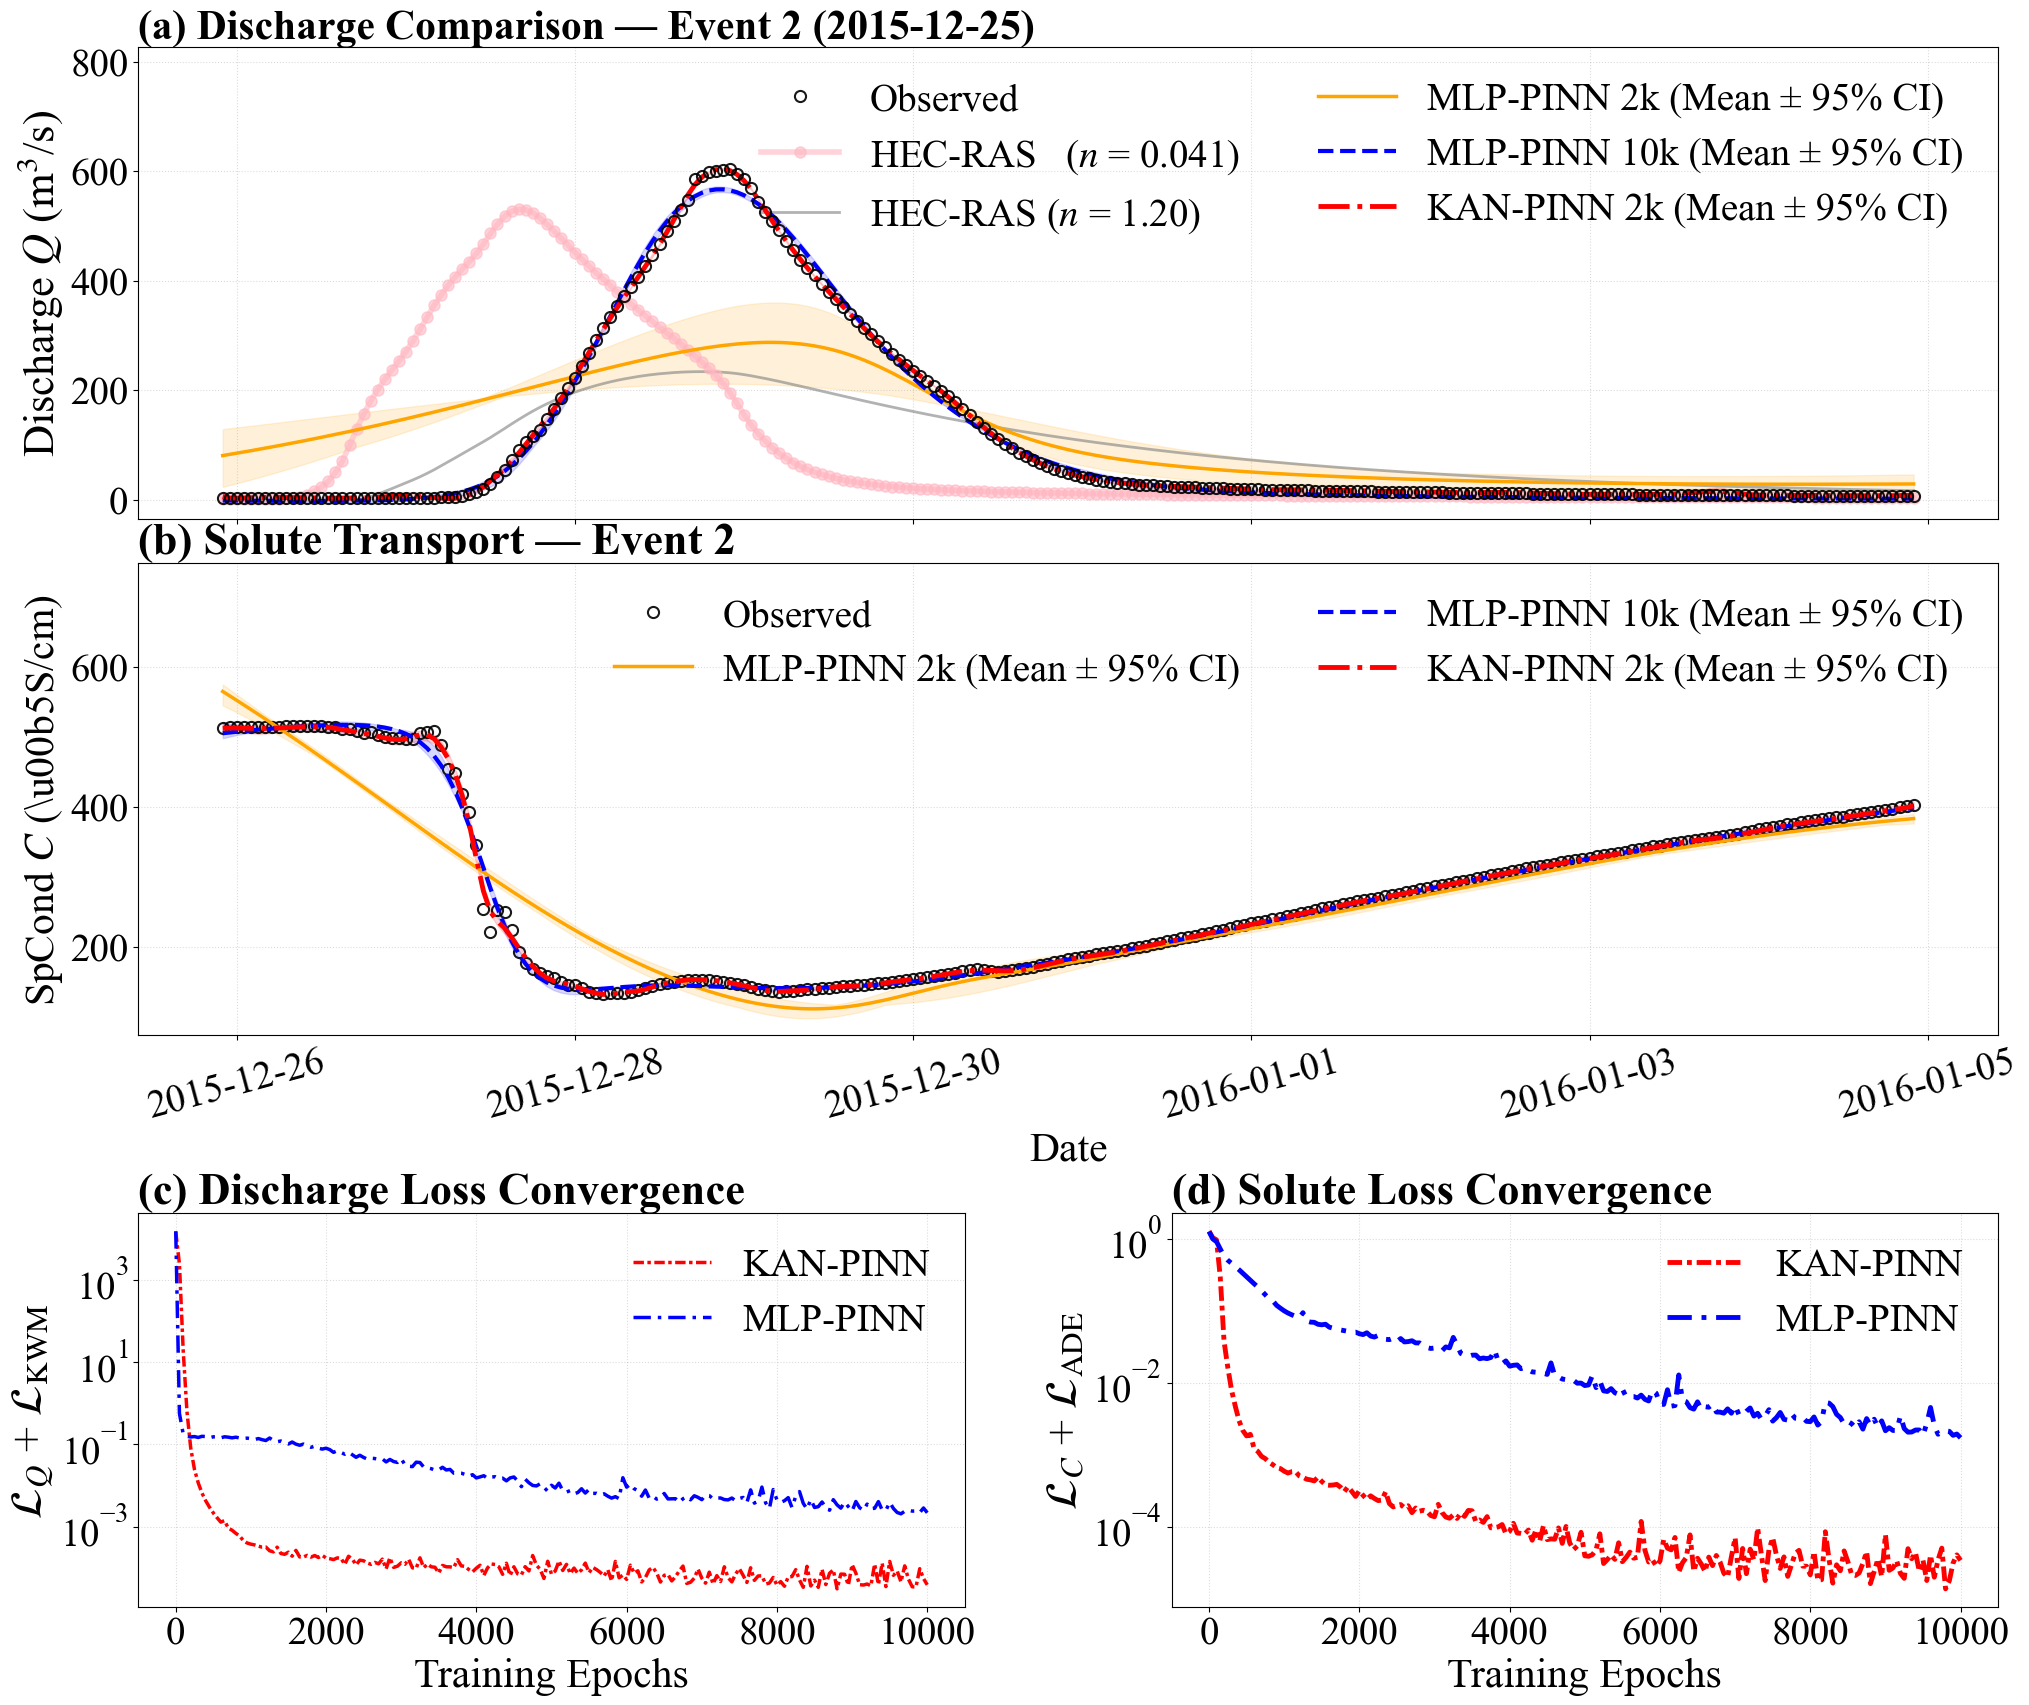

In [9]:
# =========================================================================
# Cell 9: Final 4-Panel Figure
#
# Panels (a) & (b): timeseries comparison (Style updated for clarity)
#   - Observed (Larger hollow circles)
#   - HEC-RAS (n=0.041 - Pink thick line with markers; n=1.20 - Grey thin line)
#   - MLP-PINN  2k epoch  (Orange solid line, medium thick)
#   - MLP-PINN 10k epoch  (Red dashed line, thick)
#   - KAN-PINN  2k epoch  (Blue dash-dot line, thickest)
#   * Note: KAN-PINN 10k is excluded from a & b as requested.
#
# Panels (c) & (d): loss convergence
#   - Only 10k epoch models shown (KAN‑PINN & MLP‑PINN)
#   - Color unified with (a)(b) panels
# =========================================================================
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ── Colour & Style Palette (Updated for high contrast) ────────────────────
OBS_COLOR     = '#000000'    # Black for observations
HEC_041_COLOR = '#FFB6C1'    # Light Pink (mimicking NWM3.0 in reference)
HEC_120_COLOR = '#808080'    # Grey (background reference)
MLP2K_COLOR   = '#FFA500'    # Orange
MLP10K_COLOR  = '#0000FF'    # Red (MLP unified color for all panels)
KAN2K_COLOR   = '#FF0000'   # Blue (KAN unified color for all panels)

# ── Load HEC-RAS ──────────────────────────────────────────────────────────
HECRAS_PATH = r"D:\Alhw\WRR-KAN-PINN\Data\HEC-RAS-EVENT2.xlsx"

_df_hec    = pd.read_excel(HECRAS_PATH, header=None)
hecras_041 = _df_hec.iloc[:, 0].values.astype(float)
hecras_120 = _df_hec.iloc[:, 1].values.astype(float)

t_dt  = ev_data['datetime'].values
obs_q = q_down / CFS_TO_CMS
obs_c = c_down
n_obs = len(obs_q)

def _align(q, n):
    if len(q) > n:   return q[:n]
    elif len(q) < n: return np.pad(q, (0, n - len(q)), mode='edge')
    return q

hecras_041 = _align(hecras_041, n_obs)
hecras_120 = _align(hecras_120, n_obs)

# ── Ensemble statistics ───────────────────────────────────────────────────
def get_bounds(preds, conversion=1.0):
    arr = np.array(preds) / conversion
    return (np.mean(arr, axis=0),
            np.percentile(arr,  2.5, axis=0),
            np.percentile(arr, 97.5, axis=0))

kan2k_mq,  kan2k_lq,  kan2k_uq_  = get_bounds(kan2k_results['q'],   CFS_TO_CMS)
# kan10k_mq removed for a/b
mlp2k_mq,  mlp2k_lq,  mlp2k_uq_  = get_bounds(mlp2k_results['q'],   CFS_TO_CMS)
mlp10k_mq, mlp10k_lq, mlp10k_uq_ = get_bounds(mlp10k_results['q'],  CFS_TO_CMS)

kan2k_mc,  kan2k_lc,  kan2k_uc_  = get_bounds(kan2k_results['c'],  1.0)
# kan10k_mc removed for a/b
mlp2k_mc,  mlp2k_lc,  mlp2k_uc_  = get_bounds(mlp2k_results['c'],  1.0)
mlp10k_mc, mlp10k_lc, mlp10k_uc_ = get_bounds(mlp10k_results['c'], 1.0)

# ── Convergence history ───────────────────────────────────────────────────
def hist_array(hists, key):
    return np.array([h[key] for h in hists])

kan10k_epochs = np.array(kan10k_results['hist'][0]['epochs'])
kan10k_qloss  = (hist_array(kan10k_results['hist'], 'data_loss_q') +
                 hist_array(kan10k_results['hist'], 'pde_loss_kwm'))
kan10k_closs  = (hist_array(kan10k_results['hist'], 'data_loss_c') +
                 hist_array(kan10k_results['hist'], 'pde_loss_ade'))

mlp10k_epochs = np.array(mlp10k_results['hist'][0]['epochs'])
mlp10k_qloss  = (hist_array(mlp10k_results['hist'], 'data_loss_q') +
                 hist_array(mlp10k_results['hist'], 'pde_loss_kwm'))
mlp10k_closs  = (hist_array(mlp10k_results['hist'], 'data_loss_c') +
                 hist_array(mlp10k_results['hist'], 'pde_loss_ade'))

ev_label  = EVENT2['start'].strftime('%Y-%m-%d')
date_fmt  = mdates.DateFormatter('%Y-%m-%d')

# ── Figure layout ─────────────────────────────────────────────────────────
fig = plt.figure(figsize=(24, 22))
gs  = gridspec.GridSpec(3, 2,
                         figure=fig,
                         height_ratios=[1.2, 1.2, 1.0],
                         hspace=0.4, wspace=0.25)

ax_a = fig.add_subplot(gs[0, :])
ax_b = fig.add_subplot(gs[1, :], sharex=ax_a)
ax_c = fig.add_subplot(gs[2, 0])
ax_d = fig.add_subplot(gs[2, 1])

# ─────────────────────────────────────────────────────────────────────────
# Panel (a): Discharge Q
# ─────────────────────────────────────────────────────────────────────────
# 1. Observations: Larger, hollow black circles
ax_a.plot(t_dt, obs_q, 'o', ms=8, mfc='none', mec=OBS_COLOR, mew=1.5,
          lw=0, alpha=0.9, label='Observed', zorder=10)

# 2. HEC-RAS 041: Thick pink line with circles (like NWM3.0 in reference)
ax_a.plot(t_dt, hecras_041, color=HEC_041_COLOR, ls='-', lw=4,
          marker='o', ms=8, mfc=HEC_041_COLOR, mec=HEC_041_COLOR, alpha=0.6,
          label=r'HEC-RAS   ($n$ = 0.041)', zorder=3)

# 3. HEC-RAS 120: Thin grey line (background)
ax_a.plot(t_dt, hecras_120, color=HEC_120_COLOR, ls='-', lw=2, alpha=0.6,
          label=r'HEC-RAS ($n$ = 1.20)',  zorder=2)

# 4. MLP 2k: Orange solid line
ax_a.fill_between(t_dt, mlp2k_lq, mlp2k_uq_, color=MLP2K_COLOR, alpha=0.15, zorder=1)
ax_a.plot(t_dt, mlp2k_mq, color=MLP2K_COLOR, ls='-', lw=2.5,
          label='MLP-PINN 2k (Mean \u00b1 95% CI)', zorder=6)

# 5. MLP 10k: Red dashed line, thicker
ax_a.fill_between(t_dt, mlp10k_lq, mlp10k_uq_, color=MLP10K_COLOR, alpha=0.15, zorder=1)
ax_a.plot(t_dt, mlp10k_mq, color=MLP10K_COLOR, ls='--', lw=3.0,
          label='MLP-PINN 10k (Mean \u00b1 95% CI)', zorder=7)

# 6. KAN 2k: Blue dash-dot line, thickest
ax_a.fill_between(t_dt, kan2k_lq, kan2k_uq_, color=KAN2K_COLOR, alpha=0.15, zorder=1)
ax_a.plot(t_dt, kan2k_mq, color=KAN2K_COLOR, ls='-.', lw=3.5,
          label='KAN-PINN 2k (Mean \u00b1 95% CI)', zorder=8)

ax_a.set_ylabel(r'Discharge $Q$ (m$^{3}$/s)', fontsize=32)
ax_a.set_title(f'(a) Discharge Comparison — Event 2 ({ev_label})',
               loc='left', fontweight='bold', fontsize=30)
ax_a.tick_params(axis='both', labelsize=28)
ax_a.legend(frameon=False, ncol=2, loc='upper right', fontsize=28)
ax_a.grid(True, ls=':', alpha=0.45)
plt.setp(ax_a.get_xticklabels(), visible=False)
_ylo, _yhi = ax_a.get_ylim()
ax_a.set_ylim(_ylo, _yhi * 1.30)

# ─────────────────────────────────────────────────────────────────────────
# Panel (b): Solute C
# ─────────────────────────────────────────────────────────────────────────
# 1. Observations
ax_b.plot(t_dt, obs_c, 'o', ms=8, mfc='none', mec=OBS_COLOR, mew=1.5,
          lw=0, alpha=0.9, label='Observed', zorder=5)

# 2. MLP 2k
ax_b.fill_between(t_dt, mlp2k_lc, mlp2k_uc_, color=MLP2K_COLOR, alpha=0.15, zorder=1)
ax_b.plot(t_dt, mlp2k_mc, color=MLP2K_COLOR, ls='-', lw=2.5,
          label='MLP-PINN 2k (Mean \u00b1 95% CI)', zorder=6)

# 3. MLP 10k
ax_b.fill_between(t_dt, mlp10k_lc, mlp10k_uc_, color=MLP10K_COLOR, alpha=0.15, zorder=1)
ax_b.plot(t_dt, mlp10k_mc, color=MLP10K_COLOR, ls='--', lw=3.0,
          label='MLP-PINN 10k (Mean \u00b1 95% CI)', zorder=7)

# 4. KAN 2k
ax_b.fill_between(t_dt, kan2k_lc, kan2k_uc_, color=KAN2K_COLOR, alpha=0.15, zorder=1)
ax_b.plot(t_dt, kan2k_mc, color=KAN2K_COLOR, ls='-.', lw=3.5,
          label='KAN-PINN 2k (Mean \u00b1 95% CI)', zorder=8)

ax_b.set_ylabel(r'SpCond $C$ (\u00b5S/cm)', fontsize=30)
ax_b.set_xlabel('Date', fontsize=30)
ax_b.set_title('(b) Solute Transport — Event 2', loc='left', fontweight='bold', fontsize=32)
ax_b.tick_params(axis='both', labelsize=28)
ax_b.legend(frameon=False, ncol=2, loc='upper right', fontsize=28)
ax_b.grid(True, ls=':', alpha=0.45)
ax_b.xaxis.set_major_formatter(date_fmt)
ax_b.xaxis.set_major_locator(mdates.DayLocator(interval=2))
for tk in ax_b.get_xticklabels():
    tk.set_rotation(15)
_ylo2, _yhi2 = ax_b.get_ylim()
ax_b.set_ylim(_ylo2, _yhi2 * 1.25)

pos_a = ax_a.get_position(); pos_b = ax_b.get_position()
ax_a.set_position([pos_a.x0, pos_b.y1 + 0.02, pos_a.width, pos_a.height])

# ─────────────────────────────────────────────────────────────────────────
# Panel (c): Q Loss — 10k epoch models only
# ─────────────────────────────────────────────────────────────────────────
for epochs, loss_arr, color, ls, lw, label in [
    (kan10k_epochs, kan10k_qloss, KAN2K_COLOR, (0,(3,1,1,1)), 2.5, 'KAN-PINN'),
    (mlp10k_epochs, mlp10k_qloss, MLP10K_COLOR, (0,(5,2,1,2)), 2.5, 'MLP-PINN'),
]:
    mu = loss_arr.mean(0)
    ax_c.plot(epochs, mu, color=color, ls=ls, lw=lw, label=label, zorder=6)

ax_c.set_yscale('log')
ax_c.set_xlabel('Training Epochs', fontsize=30)
ax_c.set_ylabel(r'$\mathcal{L}_{Q}$ + $\mathcal{L}_{\mathrm{KWM}}$', fontsize=32)
ax_c.set_title('(c) Discharge Loss Convergence', loc='left', fontweight='bold', fontsize=32)
ax_c.tick_params(axis='both', labelsize=28)
ax_c.legend(frameon=False, fontsize=28, loc='upper right')
ax_c.grid(True, which='both', ls=':', alpha=0.45)

# ─────────────────────────────────────────────────────────────────────────
# Panel (d): C Loss — 10k epoch models only
# ─────────────────────────────────────────────────────────────────────────
for epochs, loss_arr, color, ls, lw, label in [
    (kan10k_epochs, kan10k_closs, KAN2K_COLOR, (0,(3,1,1,1)), 3.5, 'KAN-PINN'),
    (mlp10k_epochs, mlp10k_closs, MLP10K_COLOR, (0,(5,2,1,2)), 3.5, 'MLP-PINN'),
]:
    mu = loss_arr.mean(0)
    ax_d.plot(epochs, mu, color=color, ls=ls, lw=lw, label=label, zorder=6)

ax_d.set_yscale('log')
ax_d.set_xlabel('Training Epochs', fontsize=30)
ax_d.set_ylabel(r'$\mathcal{L}_C$ + $\mathcal{L}_\mathrm{ADE}$', fontsize=32)
ax_d.set_title('(d) Solute Loss Convergence', loc='left', fontweight='bold', fontsize=32)
ax_d.tick_params(axis='both', labelsize=28)
ax_d.legend(frameon=False, fontsize=28, loc='upper right')
ax_d.grid(True, which='both', ls=':', alpha=0.45)

# ── Save ──────────────────────────────────────────────────────────────────
#plt.savefig('Fig_KAN_vs_MLP_Event2_Final.png', dpi=600, bbox_inches='tight')
#plt.savefig('Fig_KAN_vs_MLP_Event2_Final.pdf', dpi=600, bbox_inches='tight')
plt.show()
#print('Figure saved -> Fig_KAN_vs_MLP_Event2_Final.png')